## EN4554 Assignment 2

### Jayasundara A.J.M.K.K.B - 220268A

GitHub: [github.com/keshj/dl-for-vision](https://github.com/keshj/dl-for-vision)


In [1]:
import os
import random
from pathlib import Path

import numpy as np
import torch
import torchvision
from torch.utils.data import Dataset

if torch.cuda.is_available():
    device = torch.device("cuda")
elif getattr(torch.backends, "mps", None) is not None and torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(f"torch {torch.__version__} | torchvision {torchvision.__version__} | device: {device}")

torch 2.7.1+cu126 | torchvision 0.22.1+cu126 | device: cuda


In [2]:
SEED = 42

def set_seed(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def seed_worker(worker_id: int) -> None:
    """Pass as `worker_init_fn` to DataLoader so each worker is seeded too."""
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

set_seed(SEED)

#### Data — download CIFAR-10 and split 45k train / 5k val

Layout under `data/`:

```
data/
├── raw/                    # torchvision download (cifar-10-batches-py)
└── cifar10_split/
    ├── train/data.pt       # 45,000 images
    ├── val/data.pt         #  5,000 images
    └── test/data.pt        # 10,000 images
```

In [3]:
DATA_ROOT = Path("data")
RAW_DIR   = DATA_ROOT / "raw"
SPLIT_DIR = DATA_ROOT / "cifar10_split"
SPLITS    = ("train", "val", "test")
N_VAL     = 5000

CLASSES = ("airplane", "automobile", "bird", "cat", "deer",
           "dog", "frog", "horse", "ship", "truck")

def _split_path(name: str) -> Path:
    return SPLIT_DIR / name / "data.pt"

def _to_tensors(ds):
    # ds.data: (N, 32, 32, 3) uint8  ->  (N, 3, 32, 32) uint8
    x = torch.from_numpy(ds.data).permute(0, 3, 1, 2).contiguous()
    y = torch.tensor(ds.targets, dtype=torch.long)
    return x, y

def prepare_cifar10(seed: int = SEED, n_val: int = N_VAL) -> None:
    if all(_split_path(s).exists() for s in SPLITS):
        print(f"Found existing splits in {SPLIT_DIR}/ — skipping download and split.")
        return

    print("Splits not found — downloading CIFAR-10 (skipped if raw files are already present)...")
    RAW_DIR.mkdir(parents=True, exist_ok=True)
    train_full = torchvision.datasets.CIFAR10(RAW_DIR, train=True,  download=True)
    test_set   = torchvision.datasets.CIFAR10(RAW_DIR, train=False, download=True)

    x_full, y_full = _to_tensors(train_full)
    x_test, y_test = _to_tensors(test_set)

    # Fixed-seed random permutation -> same 45k/5k split every time
    g = torch.Generator().manual_seed(seed)
    perm = torch.randperm(len(x_full), generator=g)
    val_idx, train_idx = perm[:n_val], perm[n_val:]

    splits = {
        "train": (x_full[train_idx], y_full[train_idx]),
        "val":   (x_full[val_idx],   y_full[val_idx]),
        "test":  (x_test,            y_test),
    }
    for name, (x, y) in splits.items():
        _split_path(name).parent.mkdir(parents=True, exist_ok=True)
        torch.save({"images": x, "labels": y, "classes": CLASSES}, _split_path(name))
        print(f"  saved {name:5s}: {tuple(x.shape)} -> {_split_path(name)}")

def load_split(name: str):
    d = torch.load(_split_path(name))
    return d["images"], d["labels"]

prepare_cifar10()

x_train, y_train = load_split("train")
x_val,   y_val   = load_split("val")
x_test,  y_test  = load_split("test")

for name, x, y in [("train", x_train, y_train), ("val", x_val, y_val), ("test", x_test, y_test)]:
    counts = torch.bincount(y, minlength=10).tolist()
    print(f"{name:5s}: {tuple(x.shape)}  per-class counts: {counts}")

Found existing splits in data/cifar10_split/ — skipping download and split.
train: (45000, 3, 32, 32)  per-class counts: [4517, 4495, 4502, 4474, 4530, 4516, 4441, 4499, 4494, 4532]
val  : (5000, 3, 32, 32)  per-class counts: [483, 505, 498, 526, 470, 484, 559, 501, 506, 468]
test : (10000, 3, 32, 32)  per-class counts: [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]


## Per-channel normalization with training-set statistics

Mean and std are computed **only on the 45k training split** and then applied to train, val and test.

In [4]:
x = x_train.float().div_(255.0)                 # (N, 3, 32, 32) in [0, 1] with in place division
CIFAR_MEAN = x.mean(dim=(0, 2, 3))              # per-channel over N, H, W
CIFAR_STD  = x.std(dim=(0, 2, 3))
del x

print("train mean (R, G, B):", [round(v, 4) for v in CIFAR_MEAN.tolist()])
print("train std  (R, G, B):", [round(v, 4) for v in CIFAR_STD.tolist()])


class CIFARTensorDataset(Dataset):
    """uint8 images -> float in [0,1] -> optional augmentation -> per-channel normalization."""

    def __init__(self, images, labels, mean=CIFAR_MEAN, std=CIFAR_STD, augment=None):
        self.images, self.labels = images, labels
        self.mean = mean.view(3, 1, 1)
        self.std  = std.view(3, 1, 1)
        self.augment = augment

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        x = self.images[i].float().div(255.0)
        if self.augment is not None:
            x = self.augment(x)
        x = (x - self.mean) / self.std
        return x, self.labels[i]


train_ds = CIFARTensorDataset(x_train, y_train, augment=None)
val_ds   = CIFARTensorDataset(x_val,   y_val)
test_ds  = CIFARTensorDataset(x_test,  y_test)

train mean (R, G, B): [0.4916, 0.4825, 0.4469]
train std  (R, G, B): [0.247, 0.2435, 0.2617]


#### Setup:

- **Normalization.** The per-channel mean and standard deviation are computed **only on the 45k training split**, so no information from the validation or test images leaks into training. The same statistics are then applied to all three splits. After normalization, each channel has mean ≈ 0 and standard deviation ≈ 1.


## Task 1: Backpropagation

### (a) Linear, ReLU and softmax cross-entropy with explicit forward/backward


In [5]:
import math

import matplotlib.pyplot as plt
import torch.nn.functional as F

FIG_DIR = Path("report/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)


class Linear:
    def __init__(self, in_features, out_features, device="cpu", dtype=torch.float32):
        self.W = torch.randn(in_features, out_features, device=device, dtype=dtype) * math.sqrt(2.0 / in_features)
        self.b = torch.zeros(out_features, device=device, dtype=dtype)
        self.dW = torch.zeros_like(self.W)
        self.db = torch.zeros_like(self.b)

    def forward(self, x):
        self.x = x
        return x @ self.W + self.b

    def backward(self, dout):
        self.dW = self.x.T @ dout
        self.db = dout.sum(dim=0)
        return dout @ self.W.T


class ReLU:
    def forward(self, x):
        self.mask = x > 0
        return x * self.mask

    def backward(self, dout):
        return dout * self.mask


class Sigmoid:
    def forward(self, x):
        self.out = 1.0 / (1.0 + torch.exp(-x))
        return self.out

    def backward(self, dout):
        return dout * self.out * (1.0 - self.out)


class SoftmaxCrossEntropy:
    def forward(self, logits, y):
        shifted = logits - logits.max(dim=1, keepdim=True).values
        log_probs = shifted - shifted.exp().sum(dim=1, keepdim=True).log()
        self.probs = log_probs.exp()
        self.y = y
        return -log_probs[torch.arange(len(y)), y].mean()

    def backward(self):
        d = self.probs.clone()
        d[torch.arange(len(self.y)), self.y] -= 1.0
        return d / len(self.y)


class MLP:
    def __init__(self, sizes, activation=ReLU, device="cpu", dtype=torch.float32):
        self.layers = []
        for i, (fan_in, fan_out) in enumerate(zip(sizes[:-1], sizes[1:])):
            self.layers.append(Linear(fan_in, fan_out, device, dtype))
            if i < len(sizes) - 2:
                self.layers.append(activation())
        self.criterion = SoftmaxCrossEntropy()

    @property
    def linears(self):
        return [layer for layer in self.layers if isinstance(layer, Linear)]

    def forward(self, x):
        for layer in self.layers:
            x = layer.forward(x)
        return x

    def loss(self, x, y):
        return self.criterion.forward(self.forward(x), y)

    def backward(self):
        d = self.criterion.backward()
        for layer in reversed(self.layers):
            d = layer.backward(d)

    def parameters(self):
        return [p for layer in self.linears for p in (layer.W, layer.b)]

    def grads(self):
        return [g for layer in self.linears for g in (layer.dW, layer.db)]

    def sgd_step(self, lr):
        for p, g in zip(self.parameters(), self.grads()):
            p -= lr * g


def flatten_normalize(x):
    x = x.float().div(255.0)
    return ((x - CIFAR_MEAN.view(1, 3, 1, 1)) / CIFAR_STD.view(1, 3, 1, 1)).flatten(1)

#### How the backward pass works

Each layer saves what it needs in `forward`. In `backward` it receives the upstream gradient $\delta = \partial L / \partial(\text{output})$ and returns $\partial L / \partial(\text{input})$, so the layers can be chained with the chain rule. No autograd is used. For a mini-batch $X \in \mathbb{R}^{N \times d}$:

| layer | forward | backward |
|---|---|---|
| Linear | $Z = XW + b$ | $\dfrac{\partial L}{\partial W} = X^\top \delta,\quad \dfrac{\partial L}{\partial b} = \sum_n \delta_n,\quad \dfrac{\partial L}{\partial X} = \delta W^\top$ |
| ReLU | $A = \max(0, Z)$ | $\dfrac{\partial L}{\partial Z} = \delta \odot \mathbf{1}[Z > 0]$ |
| Sigmoid | $A = \sigma(Z)$ | $\dfrac{\partial L}{\partial Z} = \delta \odot A \odot (1 - A)$ |
| Softmax cross-entropy | $L = -\frac{1}{N} \sum_n \log p_{n, y_n}$ | $\dfrac{\partial L}{\partial Z} = \frac{1}{N}(P - Y_{\text{one-hot}})$ |

- The softmax and the cross-entropy are combined into one layer because it is numerically stable.
- The loss is computed from log-probabilities after subtracting the row maximum of the logits (the *log-sum-exp trick*), so `exp` never overflows.


### (b) Gradient check against autograd and centred finite differences

A small MLP (3072-64-32-10) in float64 on 16 training images. The manual gradients are compared with
1. autograd on an identical network built from `torch` ops, over every parameter, and
2. centred finite differences $\frac{L(\theta+\varepsilon) - L(\theta-\varepsilon)}{2\varepsilon}$ with $\varepsilon = 10^{-6}$, on 50 randomly chosen entries of each parameter tensor.

Relative error: $\dfrac{\lVert g_1 - g_2 \rVert}{\lVert g_1 \rVert + \lVert g_2 \rVert}$.

In [6]:
set_seed(SEED)
gc_model = MLP([3072, 64, 32, 10], dtype=torch.float64)
x_gc = flatten_normalize(x_train[:16]).double()
y_gc = y_train[:16]

gc_model.loss(x_gc, y_gc)
gc_model.backward()
manual_grads = [g.clone() for g in gc_model.grads()]

leaves = [p.clone().requires_grad_() for p in gc_model.parameters()]
h = x_gc
for i in range(0, len(leaves), 2):
    h = h @ leaves[i] + leaves[i + 1]
    if i < len(leaves) - 2:
        h = h.relu()
F.cross_entropy(h, y_gc).backward()
autograd_grads = [p.grad for p in leaves]


def rel_error(a, b):
    return ((a - b).norm() / (a.norm() + b.norm()).clamp_min(1e-20)).item()


EPS = 1e-6
gen = torch.Generator().manual_seed(SEED)
names = [f"{n}{i}" for i in range(1, 4) for n in ("W", "b")]

print(f"{'param':6s} {'shape':>12s} | {'rel err (autograd)':>18s} {'allclose':>8s} | {'rel err (fin. diff)':>19s} {'allclose':>8s}")
for name, p, g_man, g_auto in zip(names, gc_model.parameters(), manual_grads, autograd_grads):
    flat = p.view(-1)
    idx = torch.randperm(flat.numel(), generator=gen)[:50]
    fd = torch.empty(len(idx), dtype=p.dtype)
    for k, j in enumerate(idx):
        orig = flat[j].item()
        flat[j] = orig + EPS
        loss_plus = gc_model.loss(x_gc, y_gc).item()
        flat[j] = orig - EPS
        loss_minus = gc_model.loss(x_gc, y_gc).item()
        flat[j] = orig
        fd[k] = (loss_plus - loss_minus) / (2 * EPS)
    g_sub = g_man.view(-1)[idx]
    print(f"{name:6s} {str(tuple(p.shape)):>12s} | "
          f"{rel_error(g_man, g_auto):18.2e} {str(torch.allclose(g_man, g_auto)):>8s} | "
          f"{rel_error(g_sub, fd):19.2e} {str(torch.allclose(g_sub, fd)):>8s}")

param         shape | rel err (autograd) allclose | rel err (fin. diff) allclose
W1       (3072, 64) |           6.80e-17     True |            2.56e-09     True
b1            (64,) |           7.55e-17     True |            2.17e-09     True
W2         (64, 32) |           4.35e-17     True |            9.39e-10     True
b2            (32,) |           5.56e-17     True |            1.26e-09     True
W3         (32, 10) |           2.76e-17     True |            5.83e-10     True
b3            (10,) |           1.62e-17     True |            5.84e-10     True


#### Interpretation:

- **Against autograd** the relative errors are about $10^{-17}$. Both versions compute the same formulas, so the only difference is rounding error. `torch.allclose` is `True` for every parameter.
- **Against finite differences** the relative errors are about $10^{-9}$. `torch.allclose` is again `True` for every parameter.
- The finite-difference check does not use PyTorch's gradients. Since both checks agree for every layer, the manual backward pass is correct.

### (c) Training with SGD on flattened CIFAR-10

MLP 3072-512-256-10 with ReLU, plain mini-batch SGD (batch 128, learning rate 0.01, 20 epochs), using only the manual forward/backward.

In [7]:
X_tr, Y_tr = flatten_normalize(x_train).to(device), y_train.to(device)
X_va, Y_va = flatten_normalize(x_val).to(device), y_val.to(device)


def evaluate(model, X, Y, batch_size=5000):
    total_loss, correct = 0.0, 0
    for i in range(0, len(X), batch_size):
        xb, yb = X[i:i + batch_size], Y[i:i + batch_size]
        logits = model.forward(xb)
        total_loss += model.criterion.forward(logits, yb).item() * len(xb)
        correct += (logits.argmax(dim=1) == yb).sum().item()
    return total_loss / len(X), correct / len(X)


EPOCHS, BATCH_SIZE, LR = 20, 128, 0.01

set_seed(SEED)
mlp = MLP([3072, 512, 256, 10], activation=ReLU, device=device)
shuffle_gen = torch.Generator().manual_seed(SEED)

iter_losses = []
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
for epoch in range(1, EPOCHS + 1):
    perm = torch.randperm(len(X_tr), generator=shuffle_gen).to(device)
    for i in range(0, len(X_tr), BATCH_SIZE):
        idx = perm[i:i + BATCH_SIZE]
        loss = mlp.loss(X_tr[idx], Y_tr[idx])
        mlp.backward()
        mlp.sgd_step(LR)
        iter_losses.append(loss.item())

    train_loss, train_acc = evaluate(mlp, X_tr, Y_tr)
    val_loss, val_acc = evaluate(mlp, X_va, Y_va)
    for k, v in zip(history, (train_loss, train_acc, val_loss, val_acc)):
        history[k].append(v)
    print(f"epoch {epoch:2d} | train loss {train_loss:.4f} acc {train_acc:.4f} | val loss {val_loss:.4f} acc {val_acc:.4f}")

best_epoch = int(np.argmax(history["val_acc"])) + 1
print(f"\nFinal validation accuracy: {history['val_acc'][-1]:.4f}  (best {max(history['val_acc']):.4f} at epoch {best_epoch})")

epoch  1 | train loss 1.6056 acc 0.4372 | val loss 1.6761 acc 0.4106
epoch  2 | train loss 1.4671 acc 0.4921 | val loss 1.5899 acc 0.4432
epoch  3 | train loss 1.3788 acc 0.5269 | val loss 1.5406 acc 0.4554
epoch  4 | train loss 1.3025 acc 0.5576 | val loss 1.5049 acc 0.4702
epoch  5 | train loss 1.2425 acc 0.5799 | val loss 1.4730 acc 0.4772
epoch  6 | train loss 1.2200 acc 0.5821 | val loss 1.4898 acc 0.4736
epoch  7 | train loss 1.1418 acc 0.6139 | val loss 1.4483 acc 0.4962
epoch  8 | train loss 1.0979 acc 0.6333 | val loss 1.4401 acc 0.4970
epoch  9 | train loss 1.0586 acc 0.6502 | val loss 1.4399 acc 0.4938
epoch 10 | train loss 1.0226 acc 0.6565 | val loss 1.4330 acc 0.5032
epoch 11 | train loss 0.9915 acc 0.6706 | val loss 1.4415 acc 0.5024
epoch 12 | train loss 0.9398 acc 0.6909 | val loss 1.4356 acc 0.5030
epoch 13 | train loss 0.9010 acc 0.7089 | val loss 1.4298 acc 0.5106
epoch 14 | train loss 0.8614 acc 0.7239 | val loss 1.4294 acc 0.5148
epoch 15 | train loss 0.8456 acc 0

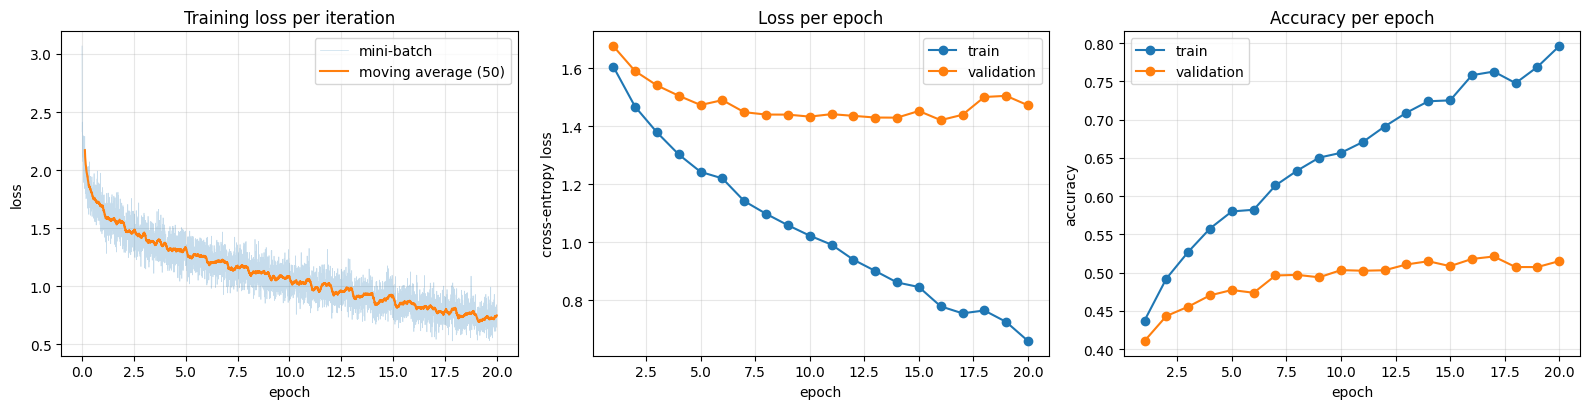

In [8]:
iters_per_epoch = math.ceil(len(X_tr) / BATCH_SIZE)
epochs_axis = np.arange(1, EPOCHS + 1)
smooth = np.convolve(iter_losses, np.ones(50) / 50, mode="valid")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
axes[0].plot(np.arange(len(iter_losses)) / iters_per_epoch, iter_losses, alpha=0.25, lw=0.5, label="mini-batch")
axes[0].plot((np.arange(len(smooth)) + 49) / iters_per_epoch, smooth, label="moving average (50)")
axes[0].set(xlabel="epoch", ylabel="loss", title="Training loss per iteration")
axes[0].legend()

axes[1].plot(epochs_axis, history["train_loss"], "o-", label="train")
axes[1].plot(epochs_axis, history["val_loss"], "o-", label="validation")
axes[1].set(xlabel="epoch", ylabel="cross-entropy loss", title="Loss per epoch")
axes[1].legend()

axes[2].plot(epochs_axis, history["train_acc"], "o-", label="train")
axes[2].plot(epochs_axis, history["val_acc"], "o-", label="validation")
axes[2].set(xlabel="epoch", ylabel="accuracy", title="Accuracy per epoch")
axes[2].legend()

for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(FIG_DIR / "t1c_training.pdf", bbox_inches="tight")
plt.show()

#### Interpretation

- Most of the loss reduction happens in the first epoch (from $\ln 10 \approx 2.30$ at initialization down to about 1.6). After that the training loss keeps falling steadily.
- **Overfitting.** Validation loss stops improving after about 10 epochs. Training accuracy, however, keeps climbing, so the train–validation gap grows. The network has 1.7M parameters, which is enough to memorize details of the 45k training images, but this does not help on new images.
- **The main limit is the architecture.** Flattening the image throws away its spatial structure. The MLP has no idea that neighbouring pixels are related. Convolutional layers fix this with *local receptive fields* and *weight sharing* across positions.

### (d) Per-layer gradient norm at initialization: sigmoid vs ReLU

Two 10-layer MLPs (3072 → 9 × 256 → 10) with the same He initialization and the same batch of 512 training images, differing only in the hidden activation. One forward/backward pass, then $\lVert \partial L / \partial W_\ell \rVert_F$ for every layer.

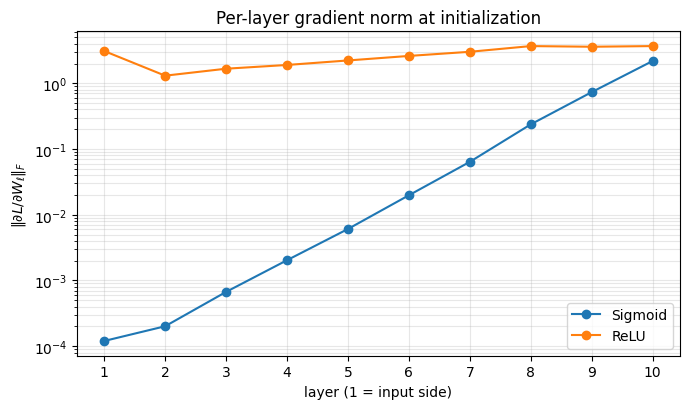

layer    Sigmoid       ReLU
    1   1.20e-04   3.10e+00
    2   2.01e-04   1.31e+00
    3   6.70e-04   1.67e+00
    4   2.03e-03   1.90e+00
    5   6.07e-03   2.23e+00
    6   1.98e-02   2.61e+00
    7   6.38e-02   3.01e+00
    8   2.37e-01   3.68e+00
    9   7.33e-01   3.60e+00
   10   2.18e+00   3.68e+00
Sigmoid: layer 10 / layer 1 gradient-norm ratio = 18165.3
ReLU: layer 10 / layer 1 gradient-norm ratio = 1.2


In [9]:
x_d, y_d = flatten_normalize(x_train[:512]).to(device), y_train[:512].to(device)
deep_sizes = [3072] + [256] * 9 + [10]

grad_norms = {}
for name, act in [("Sigmoid", Sigmoid), ("ReLU", ReLU)]:
    set_seed(SEED)
    deep = MLP(deep_sizes, activation=act, device=device)
    deep.loss(x_d, y_d)
    deep.backward()
    grad_norms[name] = [layer.dW.norm().item() for layer in deep.linears]

layers_axis = np.arange(1, len(deep_sizes))
fig, ax = plt.subplots(figsize=(7, 4.2))
for name, norms in grad_norms.items():
    ax.semilogy(layers_axis, norms, "o-", label=name)
ax.set(xlabel="layer (1 = input side)", ylabel=r"$\|\partial L / \partial W_\ell\|_F$",
       title="Per-layer gradient norm at initialization", xticks=layers_axis)
ax.grid(alpha=0.3, which="both")
ax.legend()
plt.tight_layout()
fig.savefig(FIG_DIR / "t1d_grad_norms.pdf", bbox_inches="tight")
plt.show()

print(f"{'layer':>5s} {'Sigmoid':>10s} {'ReLU':>10s}")
for l, s, r in zip(layers_axis, grad_norms["Sigmoid"], grad_norms["ReLU"]):
    print(f"{l:5d} {s:10.2e} {r:10.2e}")
for name, norms in grad_norms.items():
    print(f"{name}: layer 10 / layer 1 gradient-norm ratio = {norms[-1] / norms[0]:.1f}")

#### Interpretation

- **Sigmoid: vanishing gradients.** The gradient norm drops by about $3\times$ for every layer moved back from the output. Layer 1 (next to the input) gets a gradient about **18,000× smaller** than layer 10. This is the *vanishing gradient* problem.
- **ReLU: gradients keep their scale.** All ten layers have gradient norms within a factor of about 3 of each other (layer 10 / layer 1 ratio = 1.2).

**Reason:** By the chain rule, going back one layer multiplies the gradient by the transposed weight matrix and then by the derivative of the activation:
$$\delta_\ell = (\delta_{\ell+1} W_{\ell+1}^\top) \odot f'(Z_\ell).$$
